# POST-PHASE-13 H2B-B1 — Objective-Only Localizer Training Review

## 1. Governance / Adaptive-Development Disclosure

This notebook is **READ-ONLY**. It performs no training, no localizer inference and no
segmentation inference; it only reads on-disk artifacts.

H2B is adaptive VAL development informed by:
- Phase 13 `REVISE_LOCALIZER`
- H1 acceptance-only insufficiency
- `H2A_SELECTION_REDESIGN_PARTIAL`

The H2B objective and `gamma = 2.0` were frozen **before** H2B training. No objective grid was
run. VAL remains development data. H2B results do **not** replace final TEST evaluation.
TEST remains untouched until Phase 39.


In [1]:

import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (10, 5)

ROOT = Path(r"D:\Softfors\jup")
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"
EID = ("post_phase13_h2b_kub_localizer_r512_h128_sigmaeq075_"
       "softtargetfocalgamma2_deploymentbalance_seed42_clean_v3")
EXP = ROOT / "experiments" / EID
CK = ROOT / "checkpoints" / EID

def sha(p):
    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p
    return hashlib.sha256(p.read_bytes()).hexdigest()

hist = pd.read_csv(EXP / "history.csv")
te = json.loads((AUDITS / "post_phase13_h2b_b1_training_evaluation.json").read_text("utf-8"))
sa = json.loads((AUDITS / "post_phase13_h2b_best_checkpoint_standalone_evaluation.json").read_text("utf-8"))
print("Environment OK | epochs:", len(hist))


Environment OK | epochs: 46


## 2. H2A Partial Outcome and H2B Rationale

H2A adjudication returned **`H2A_SELECTION_REDESIGN_PARTIAL`**: checkpoint-selection redesign
produced reproducible localizer-level and downstream improvement, but the complete GT-free
regional path remained substantially below GLOBAL. Selection alone was not sufficient.

H2A also left a substantial off-target proposal burden (pixel any-hit precision ~0.276).

H2B therefore asks: can a **soft-target objective** that treats the complete frozen Gaussian
target as continuous supervision improve heatmap discrimination and proposal precision while
preserving object coverage — with everything else held fixed?

This is a **hypothesis**, not a claim.


## 3. Protocol Identity

`reports/audits/post_phase13_h2b_protocol_frozen.json` —
`SUPERVISOR_FROZEN_H2B_OBJECTIVE_ONLY_READY_FOR_B1_AUTHORIZATION`


In [2]:

print("experiment_id:", EID)
print("protocol sha:", sha(AUDITS / "post_phase13_h2b_protocol_frozen.json"))
print("protocol_identity:", te["bindings"]["h2b_protocol_sha"][:16], "...")
print("H2A adjudication sha:", te["bindings"]["h2a_adjudication_sha"])
print("runner sha:", te["bindings"]["runner_sha"])
print("config sha:", te["bindings"]["config_sha"])


experiment_id: post_phase13_h2b_kub_localizer_r512_h128_sigmaeq075_softtargetfocalgamma2_deploymentbalance_seed42_clean_v3
protocol sha: 22d4e363a9375bc12828c944b1583921efa77d45b6df7d6387738d13d950949e
protocol_identity: 22d4e363a9375bc1 ...
H2A adjudication sha: 02af0558696880f5842abaefbc8f30e5b44b20a700350bd70f963e0b844aada6
runner sha: 444f0ea7b5f6ce76c3d0955febfc67ebd0c36a80913604384ded054c443f7ddd
config sha: 0ee34404c67e36aa27ef880c59295208f662908af996cf634f6a922875340f12


## 4. One-Axis Scientific Change

Exactly **one** new scientific axis: **LOSS / OBJECTIVE SEMANTICS**.

`CenterNetFocalLoss(alpha=2.0, beta=4.0)` → `SoftTargetFocalBCE(gamma=2.0)`

Everything else UNCHANGED: architecture, target, sigma, data, augmentation, optimizer,
scheduler, checkpoint selection, proposal config, fusion.


In [3]:

d = json.loads((AUDITS / "post_phase13_h2b_b1_execution_diff_vs_h2a.json").read_text("utf-8"))
print("one-axis diff status:", d["status"])
print("scientific_axis_differences:", d["scientific_axis_differences"], "->", d["scientific_axis"])
print("gradient_affecting_beyond_criterion:", d["gradient_affecting_differences_beyond_criterion_objective"])
for k in ("architecture", "target", "optimizer", "scheduler", "data", "augmentation", "seed",
          "checkpoint_selection", "proposal_config", "initialization", "warm_start"):
    print(f"  {k}: {d[k]}")


one-axis diff status: PASS
scientific_axis_differences: 1 -> LOSS / OBJECTIVE
gradient_affecting_beyond_criterion: 0
  architecture: UNCHANGED
  target: UNCHANGED
  optimizer: UNCHANGED
  scheduler: UNCHANGED
  data: UNCHANGED
  augmentation: UNCHANGED
  seed: UNCHANGED
  checkpoint_selection: UNCHANGED
  proposal_config: UNCHANGED
  initialization: FRESH_FROM_SCRATCH_SEED42
  warm_start: NO


## 5. SoftTargetFocalBCE — Exact Frozen Formula

```
p          = sigmoid(z)
bce        = BCEWithLogits(z, y, reduction="none")
modulation = |p - y| ** gamma
loss_map   = modulation * bce
L          = mean(loss_map)
```

equivalently

```
L = mean( |sigmoid(z) - y|^2 * BCEWithLogits(z, y) )        # gamma = 2.0 FIXED
```

Modulation **not detached**. Target asserted finite and in `[0,1]` — never silently clamped.
No Dice, no alpha/beta, no auxiliary loss, no regularizer, no class weight.


In [4]:

print("loss class:", te["loss"]["class"])
print("loss label:", te["loss"]["label"])
print("gamma:", te["loss"]["gamma"])
print("formula:", te["loss"]["formula"])
print("modulation detached:", te["loss"]["modulation_detached"])
print("dice term:", te["loss"]["dice_term"], "| auxiliary loss:", te["loss"]["auxiliary_loss"])
print("objective_change_id:", te["loss"]["objective_change_id"])
print("stale loss_alpha present:", te["loss"]["stale_loss_alpha_present"])
print("stale loss_beta present:", te["loss"]["stale_loss_beta_present"])


loss class: src.losses.soft_target_focal_bce.SoftTargetFocalBCE
loss label: H2B_SOFT_TARGET_FOCAL_BCE_GAMMA2
gamma: 2.0
formula: mean( |sigmoid(z) - y|^2 * BCEWithLogits(z, y) )
modulation detached: NO
dice term: NONE | auxiliary loss: NONE
objective_change_id: H2B_OBJECTIVE_ONLY_SOFT_TARGET_FOCAL_BCE_GAMMA2
stale loss_alpha present: False
stale loss_beta present: False


## 6. Synthetic Loss / Gradient Audit (CPU-only)

`reports/audits/post_phase13_h2b_soft_target_focal_loss_unit_audit.json`


In [5]:

ua = json.loads((AUDITS / "post_phase13_h2b_soft_target_focal_loss_unit_audit.json").read_text("utf-8"))
print("status:", ua["status"], "| execution:", ua["execution"])
print("modulation detached:", ua["modulation_detached"])
for k, v in ua["checks"].items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")
g = pd.read_csv(TABLES / "post_phase13_h2b_soft_target_focal_gradient_sanity.csv")
print("gradient sanity rows:", len(g))


status: PASS | execution: CPU_ONLY_SYNTHETIC
modulation detached: NO
  [PASS] all_losses_and_gradients_finite
  [PASS] no_nan_no_inf
  [PASS] y0_loss_increases_with_p
  [PASS] y1_loss_increases_as_p_to_0
  [PASS] soft_target_minimised_near_p_equals_y
  [PASS] symmetry_L_y0_q_equals_L_y1_1mq
  [PASS] modulation_not_detached
  [PASS] all_rows_expected_direction_pass
  [PASS] target_out_of_range_rejected
  [PASS] target_nonfinite_rejected
gradient sanity rows: 35


## 7. Population

TRAIN 770 FULL_FIELD / 1161 components · VAL 103 FULL_FIELD / 152 components · ROI EXCLUDED ·
manifest `phase4_v3` · taxonomy `kub_size_clean_v3_v1`.


In [6]:

print("TRAIN:", te["training_contract"]["TRAIN"])
print("VAL:", te["training_contract"]["VAL"])
print("manifest:", te["training_contract"]["manifest"])
print("taxonomy:", te["training_contract"]["taxonomy"])
print("input:", te["training_contract"]["input"], "| heatmap:", te["training_contract"]["heatmap"],
      "| sigma:", te["training_contract"]["sigma"])


TRAIN: 770 FULL_FIELD / 1161 components
VAL: 103 FULL_FIELD / 152 components
manifest: phase4_v3
taxonomy: kub_size_clean_v3_v1
input: 512 x 512 | heatmap: 128 x 128 | sigma: 0.75


## 8. Fresh Initialization Semantics


In [7]:

for k, v in te["initialization_semantics"].items():
    print(f"  {k}: {v}")


  INITIALIZATION: FRESH_FROM_SCRATCH_SEED42
  WARM_START: NO
  PRETRAINED_LOCALIZER_STATE: NONE
  loaded_h2a_or_phase13_weights: NO
  seed: 42


## 9. Frozen Training Contract


In [8]:

for k, v in te["training_contract"].items():
    print(f"  {k}: {v}")


  TRAIN: 770 FULL_FIELD / 1161 components
  VAL: 103 FULL_FIELD / 152 components
  manifest: phase4_v3
  taxonomy: kub_size_clean_v3_v1
  input: 512 x 512
  heatmap: 128 x 128
  sigma: 0.75
  optimizer: AdamW
  lr: 0.0001
  weight_decay: 0.0001
  scheduler: CosineAnnealingLR(T_max=100)
  batch: 4
  amp: same accepted H2A semantics
  seed: 42
  augmentation: same Phase13/H2A semantics
  workers: 0
  max_epochs: 100
  early_stopping_patience: 15
  test: forbidden


## 10. Frozen Proposal Evaluation — ONE configuration only


In [9]:

for k, v in te["proposal_configuration"].items():
    print(f"  {k}: {v}")


  threshold: 0.1
  margin: 0.2
  top_k: 5
  nms_iou: 0.3
  grid: NONE
  threshold_search: NONE


## 11. Unchanged H2A Checkpoint Selection

The H2B run inherits the accepted H2A six-term deployment-balanced rule verbatim.


In [10]:

for k, v in te["selection_rule"].items():
    print(f"  {k}: {v}")


  tuple: ['DEPLOYMENT_BALANCE_HMEAN_P_TINY90_OVERALL90', 'tiny_recall90', 'overall_recall90', 'PROPOSAL_PIXEL_ANY_HIT_PRECISION', '-mean_roi_area_fraction', '-val_loss']
  comparison: STRICT_LEXICOGRAPHIC_GREATER_THAN
  ties: BAD_EPOCH
  patience: 15
  unchanged_from_h2a: YES
  source: H2A_DEPLOYMENT_BALANCED_6TERM_CARRY_FORWARD


## 12. Complete Epoch-by-Epoch Table

One completed epoch per row — **all 46 epochs, untruncated, no ellipsis**.


In [11]:

import pandas as _pd
_pd.set_option("display.max_rows", None)
_pd.set_option("display.max_columns", None)
_pd.set_option("display.width", 0)
_pd.set_option("display.max_colwidth", None)

_ecols = ["epoch", "train_loss", "val_loss", "proposal_pixel_any_hit_precision",
          "tiny_recall90", "overall_recall90", "deployment_balance_hmean",
          "proposal_total_count", "mean_roi_area_fraction", "selection_tuple",
          "is_new_best", "bad_epochs"]
print("=" * 100)
print(f"COMPLETE EPOCH TABLE — {len(hist)} / {len(hist)} rows")
print("=" * 100)
print(hist[_ecols].to_string(index=False))
print()
assert len(hist) == 46, f"expected 46 epochs, got {len(hist)}"
assert hist.epoch.is_unique and int(hist.epoch.iloc[0]) == 1
assert bool((hist.epoch.diff().dropna() == 1).all())
print(f"CONFIRMED: {len(hist)} contiguous epochs 1..{int(hist.epoch.iloc[-1])}, no duplicates")


COMPLETE EPOCH TABLE — 46 / 46 rows
 epoch  train_loss  val_loss  proposal_pixel_any_hit_precision  tiny_recall90  overall_recall90  deployment_balance_hmean  proposal_total_count  mean_roi_area_fraction                                                                                                                     selection_tuple  is_new_best  bad_epochs
     1    0.001105  0.000924                          0.000000       0.000000          0.000000                  0.000000                     0                0.000000                                                                                  [0.0, 0.0, 0.0, 0.0, -0.0, -0.0009236272039393393]         True           0
     2    0.000809  0.000738                          0.000000       0.000000          0.000000                  0.000000                     0                0.000000                                                                                   [0.0, 0.0, 0.0, 0.0, -0.0, -0.000737571240349028]         True  

## 13. Train / VAL Loss Curves

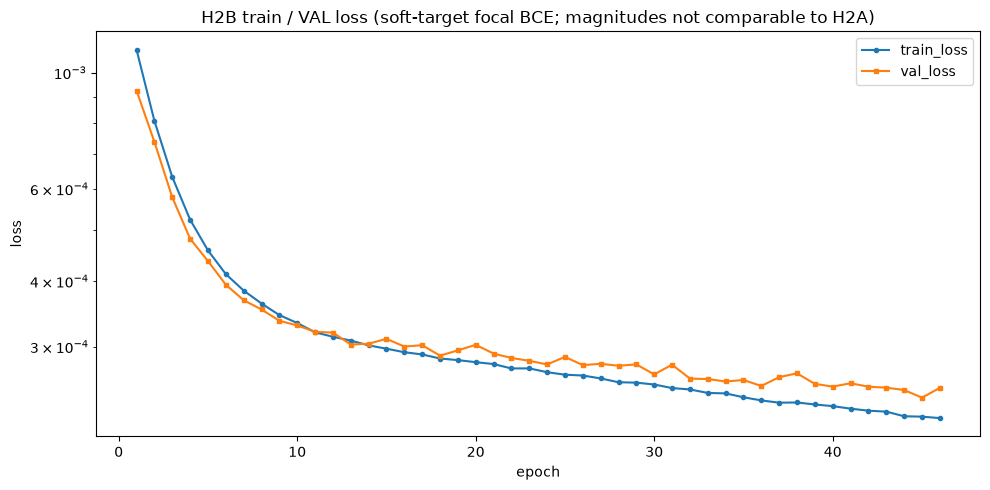

In [12]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.train_loss, marker="o", ms=3, label="train_loss")
ax.plot(hist.epoch, hist.val_loss, marker="s", ms=3, label="val_loss")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_yscale("log")
ax.set_title("H2B train / VAL loss (soft-target focal BCE; magnitudes not comparable to H2A)")
ax.legend(); plt.tight_layout(); plt.show()


## 14. P / T / O Trajectories

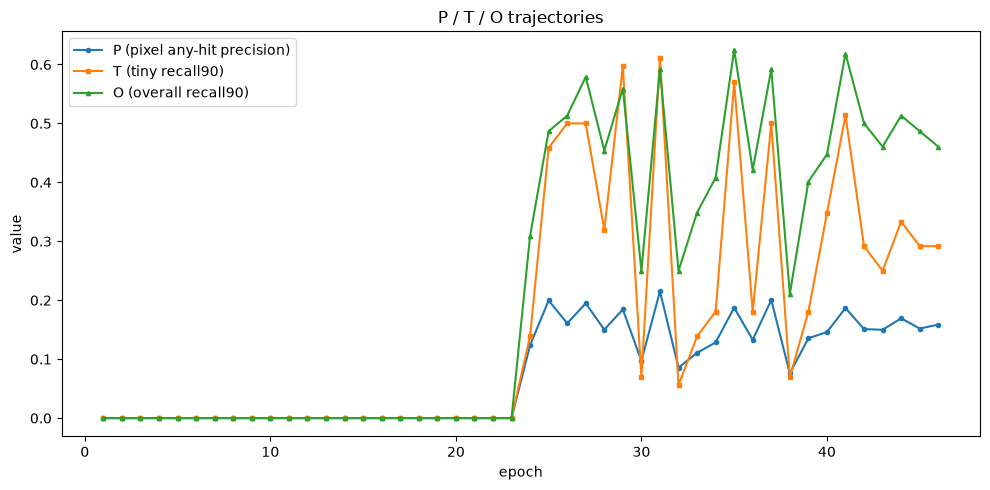

In [13]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.proposal_pixel_any_hit_precision, marker="o", ms=3, label="P (pixel any-hit precision)")
ax.plot(hist.epoch, hist.tiny_recall90, marker="s", ms=3, label="T (tiny recall90)")
ax.plot(hist.epoch, hist.overall_recall90, marker="^", ms=3, label="O (overall recall90)")
ax.set_xlabel("epoch"); ax.set_ylabel("value"); ax.set_title("P / T / O trajectories")
ax.legend(); plt.tight_layout(); plt.show()


## 15. Deployment-Balance Trajectory

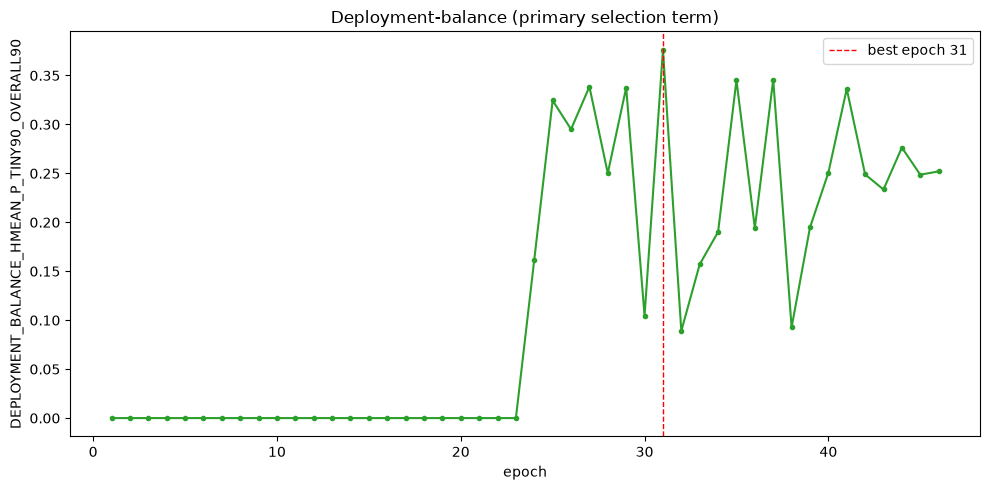

best epoch: 31 | best hmean: 0.3762759719105191


In [14]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.deployment_balance_hmean, marker="o", ms=3, color="tab:green")
be = int(hist.loc[hist.is_new_best.astype(bool), "epoch"].iloc[-1])
ax.axvline(be, color="red", ls="--", lw=1, label=f"best epoch {be}")
ax.set_xlabel("epoch"); ax.set_ylabel("DEPLOYMENT_BALANCE_HMEAN_P_TINY90_OVERALL90")
ax.set_title("Deployment-balance (primary selection term)"); ax.legend()
plt.tight_layout(); plt.show()
print("best epoch:", be, "| best hmean:", float(hist.loc[hist.epoch == be, "deployment_balance_hmean"].iloc[0]))


## 16. Proposal Count / Union-Area Trajectory

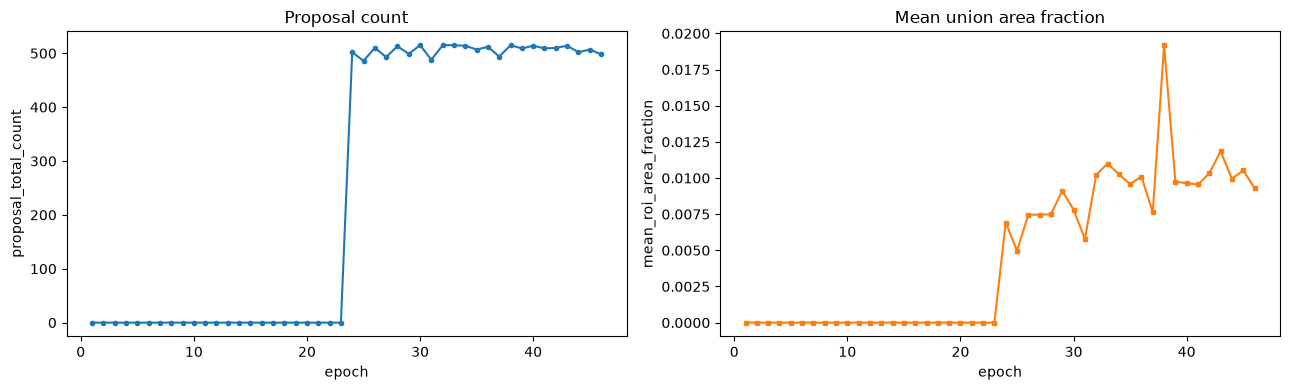

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.epoch, hist.proposal_total_count, marker="o", ms=3, color="tab:blue")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("proposal_total_count"); axes[0].set_title("Proposal count")
axes[1].plot(hist.epoch, hist.mean_roi_area_fraction, marker="s", ms=3, color="tab:orange")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("mean_roi_area_fraction"); axes[1].set_title("Mean union area fraction")
plt.tight_layout(); plt.show()


## 17. Score-Distribution Trajectory

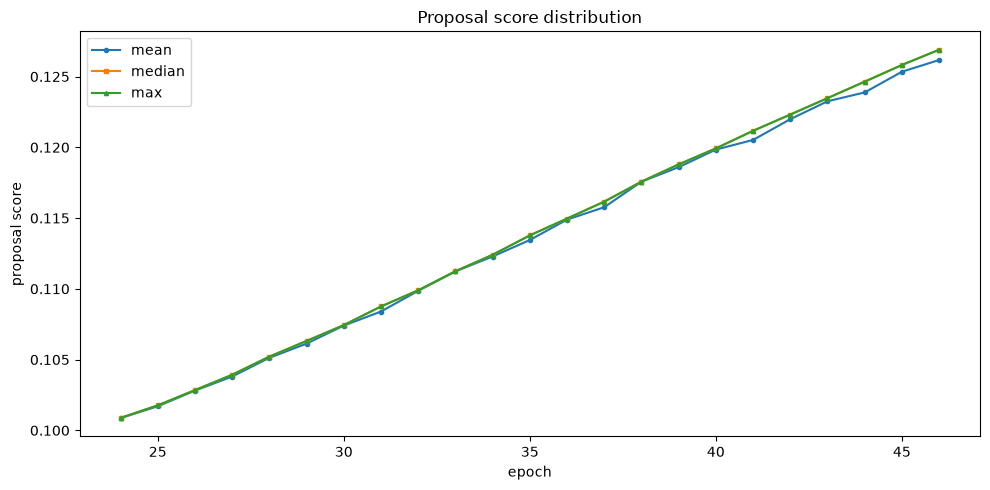

In [16]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.proposal_score_mean, marker="o", ms=3, label="mean")
ax.plot(hist.epoch, hist.proposal_score_median, marker="s", ms=3, label="median")
ax.plot(hist.epoch, hist.proposal_score_max, marker="^", ms=3, label="max")
ax.set_xlabel("epoch"); ax.set_ylabel("proposal score"); ax.set_title("Proposal score distribution")
ax.legend(); plt.tight_layout(); plt.show()


## 18. Score-Saturation Trajectory

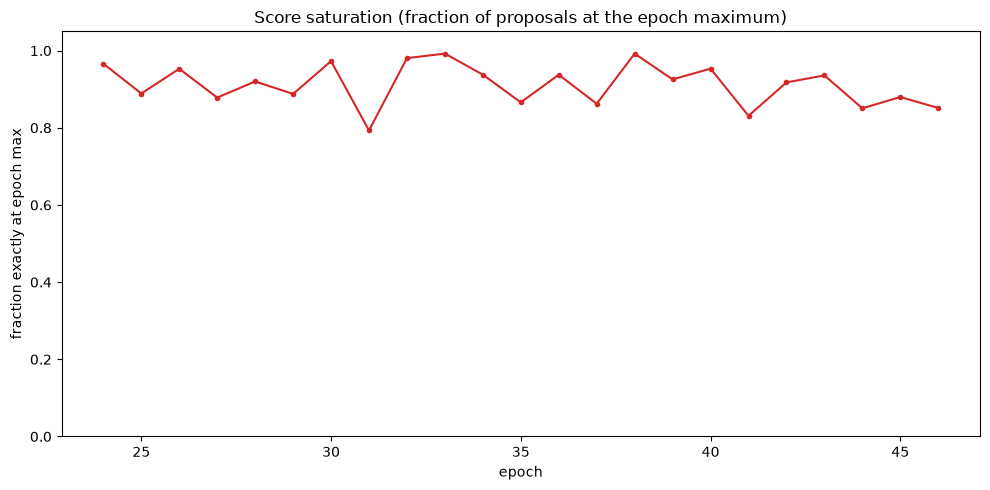

In [17]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.fraction_proposals_exactly_at_epoch_max_score, marker="o", ms=3, color="tab:red")
ax.set_ylim(0, 1.05)
ax.set_xlabel("epoch"); ax.set_ylabel("fraction exactly at epoch max")
ax.set_title("Score saturation (fraction of proposals at the epoch maximum)")
plt.tight_layout(); plt.show()


## 19. ROC-AUC / PR-AUC Trajectory

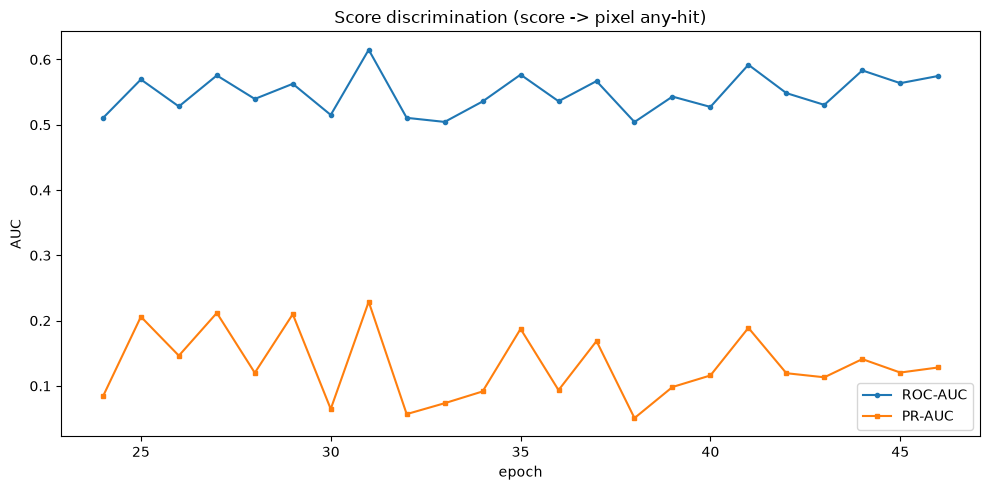

In [18]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.proposal_roc_auc_score_to_pixel_any_hit, marker="o", ms=3, label="ROC-AUC")
ax.plot(hist.epoch, hist.proposal_pr_auc_score_to_pixel_any_hit, marker="s", ms=3, label="PR-AUC")
ax.set_xlabel("epoch"); ax.set_ylabel("AUC"); ax.set_title("Score discrimination (score -> pixel any-hit)")
ax.legend(); plt.tight_layout(); plt.show()


## 20. Head-Weight / Bias Diagnostics

**DIAGNOSTIC ONLY — never used for checkpoint selection or stopping.**


In [19]:

for k, v in sa["head_statistics"].items():
    print(f"  {k}: {v}")


  head_weight_min: -0.1687416136264801
  head_weight_max: -0.15661291778087616
  head_weight_mean: -0.16419075429439545
  head_weight_std: 0.0032218785490840673
  positive_weight_count: 0
  negative_weight_count: 16
  abs_max_over_abs_mean: 1.027716875076294
  head_bias: -2.1040868759155273
  sigmoid_head_bias: 0.108700230717659
  role: DIAGNOSTIC_ONLY__NOT_USED_FOR_CHECKPOINT_SELECTION


## 21. Independent Selection Replay

In [20]:

rp = json.loads((AUDITS / "post_phase13_h2b_b1_selection_replay_verification.json").read_text("utf-8"))
print("status:", rp["status"])
print("mismatch_count:", rp["mismatch_count"])
print("replayed best_epoch:", rp["replayed"]["best_epoch"], "| stored:", rp["stored"]["best_epoch"])
print("max_abs_term_diff:", rp["max_abs_term_diff"])
print("final bad_epochs:", rp["replayed"]["final_bad_epochs"])
print("trajectory reproduction vs H2A:", rp["trajectory_reproduction_vs_h2a"])


status: PASS
mismatch_count: 0
replayed best_epoch: 31 | stored: 31
max_abs_term_diff: 7.19910242530375e-17
final bad_epochs: 15
trajectory reproduction vs H2A: NOT_PERFORMED__SEC11_OBJECTIVE_CHANGED


## 22. Best-Checkpoint Standalone Proposal Evaluation

In [21]:

m = sa["metrics"]
for k in ("proposal_total_count", "proposal_count_per_image", "proposal_pixel_any_hit_precision",
          "proposal_bbox_any_hit_precision", "tiny_recall90", "overall_recall90",
          "overall_recall50", "any_overlap_recall", "mean_coverage", "mean_proposal_union_area",
          "score_max", "score_iqr", "fraction_exactly_at_max",
          "roc_auc_score_to_pixel_any_hit", "pr_auc_score_to_pixel_any_hit"):
    print(f"  {k}: {m[k]}")


  proposal_total_count: 488
  proposal_count_per_image: 4.737864077669903
  proposal_pixel_any_hit_precision: 0.2151639344262295
  proposal_bbox_any_hit_precision: 0.21311475409836064
  tiny_recall90: 0.6111111111111112
  overall_recall90: 0.5921052631578947
  overall_recall50: 0.6973684210526315
  any_overlap_recall: 0.7368421052631579
  mean_coverage: 0.6778087714762865
  mean_proposal_union_area: 0.005777940678754471
  score_max: 0.10875558853149414
  score_iqr: 0.0
  fraction_exactly_at_max: 0.7930327868852459
  roc_auc_score_to_pixel_any_hit: 0.6149073728708193
  pr_auc_score_to_pixel_any_hit: 0.22895342337838293


## 23. Size-Stratified Results

In [22]:

st = pd.read_csv(TABLES / "post_phase13_h2b_best_checkpoint_size_stratified.csv")
print(st.to_string(index=False))


stratum  n_components  covered90_count  covered90_rate  covered50_count  covered50_rate  any_overlap_count  any_overlap_rate  mean_coverage  mean_component_pixels
   TINY            72               44        0.611111               45        0.625000                 46          0.638889       0.624334             709.472222
  SMALL            28               16        0.571429               18        0.642857                 19          0.678571       0.624910            1575.964286
 MEDIUM            36               22        0.611111               30        0.833333                 32          0.888889       0.808771            4140.611111
  LARGE            16                8        0.500000               13        0.812500                 15          0.937500       0.716354           23688.500000
    ALL           152               90        0.592105              106        0.697368                112          0.736842       0.677809            4100.572368


## 24. Difficult Frozen Cohorts

In [23]:

print("hard_tiny:", json.dumps(sa["metrics"]["hard_tiny"]))
print("global_empty:", json.dumps(sa["metrics"]["global_empty"]))
print("multi_component:", json.dumps(sa["metrics"]["multi_component"]))


hard_tiny: {"n": 15, "covered90": 5, "covered90_rate": 0.3333333333333333, "any_overlap": 6}
global_empty: {"n": 8, "covered90": 2, "covered90_rate": 0.25, "any_overlap": 4}
multi_component: {"n": 98, "covered90": 52, "covered90_rate": 0.5306122448979592}


## 25. H2B vs H2A Localizer Comparison

Descriptive development comparison. **No superiority claim. No significance language.
No checkpoint re-selection from this comparison.**


In [24]:

cmp = pd.read_csv(TABLES / "post_phase13_h2b_vs_h2a_localizer_comparison.csv")
print(cmp.to_string(index=False))


                        quantity  phase13_best_epoch53  h2a_best_epoch83   h2b_best  delta_h2b_minus_h2a
            proposal_total_count            494.000000        457.000000 488.000000            31.000000
proposal_pixel_any_hit_precision              0.246964          0.275711   0.215164            -0.060547
 proposal_bbox_any_hit_precision              0.248988          0.273523   0.213115            -0.060408
                   tiny_recall90              0.680556          0.694444   0.611111            -0.083333
                overall_recall90              0.598684          0.638158   0.592105            -0.046053
                overall_recall50              0.789474          0.822368   0.697368            -0.125000
              any_overlap_recall              0.848684          0.875000   0.736842            -0.138158
                   mean_coverage              0.758402          0.787897   0.677809            -0.110088
        mean_proposal_union_area              0.004846 

## 26. Phase-13 Historical Context

Phase-13 epoch-53 values appear as the leftmost comparator column above. Phase 13 is
**historical context only** — H2B's immediate baseline is H2A, not Phase 13.


In [25]:

print(cmp[["quantity", "phase13_best_epoch53", "h2a_best_epoch83", "h2b_best"]].to_string(index=False))


                        quantity  phase13_best_epoch53  h2a_best_epoch83   h2b_best
            proposal_total_count            494.000000        457.000000 488.000000
proposal_pixel_any_hit_precision              0.246964          0.275711   0.215164
 proposal_bbox_any_hit_precision              0.248988          0.273523   0.213115
                   tiny_recall90              0.680556          0.694444   0.611111
                overall_recall90              0.598684          0.638158   0.592105
                overall_recall50              0.789474          0.822368   0.697368
              any_overlap_recall              0.848684          0.875000   0.736842
                   mean_coverage              0.758402          0.787897   0.677809
        mean_proposal_union_area              0.004846          0.004795   0.005778
                       score_max              0.125065          0.141637   0.108756
                       score_iqr              0.000533          0.001654   0

## 27. Limitations

1. H2B is a single-seed adaptive VAL-development experiment.
2. H2B train/val loss magnitudes are **not** comparable to H2A/Phase-13 — the objective changed.
   There is no loss-trajectory reproduction gate across branches.
3. The deployment-balanced rule cannot discriminate epochs before proposals appear.
4. Descriptive comparison only — no statistical superiority claim.
5. No threshold search, no proposal grid, no gamma sweep.
6. Head statistics are diagnostic only and never influenced selection.
7. TEST remains untouched; these are development-data results only.


## 28. Explicit Downstream Stop Boundary

**H2B-B1 DOES NOT run downstream segmentation.**

Not authorized and not performed:
- UNet / Attention U-Net / UNet++ / DeepLabV3+ regional evaluation
- H2B-B2
- H1 selective acceptance
- fusion redesign
- objective change or another gamma
- representation / head redesign
- H3, Phase 14
- TEST access

**H2B outcome is NOT adjudicated here.**


## 29. Adaptive-Development Disclosure

H2B is adaptive VAL development informed by Phase 13 `REVISE_LOCALIZER`, H1 insufficiency and
`H2A_SELECTION_REDESIGN_PARTIAL`. The objective and `gamma = 2.0` were frozen **before** H2B
training and no objective grid was run. VAL remains development data. H2B results do not
replace final TEST evaluation. TEST remains untouched until Phase 39.


## 30. Artifact SHA Registry

In [26]:

artifacts = [
    "reports/audits/post_phase13_h2b_protocol_frozen.json",
    "reports/audits/post_phase13_h2b_soft_target_focal_loss_unit_audit.json",
    "reports/audits/post_phase13_h2b_b1_execution_diff_vs_h2a.json",
    "reports/audits/post_phase13_h2b_b1_pre_fix_execution_invalidation.json",
    "reports/audits/post_phase13_h2b_b1_defect_linkage.json",
    "reports/audits/post_phase13_h2b_b1_provenance_repair_tests.json",
    "reports/audits/post_phase13_h2b_b1_training_start.json",
    "reports/audits/post_phase13_h2b_b1_training_completion.json",
    "reports/audits/post_phase13_h2b_b1_selection_replay_verification.json",
    "reports/audits/post_phase13_h2b_best_checkpoint_standalone_evaluation.json",
    "reports/audits/post_phase13_h2b_b1_training_evaluation.json",
    "reports/tables/post_phase13_h2b_best_checkpoint_case_proposals.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_proposals.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_component_coverage.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_size_stratified.csv",
    "reports/tables/post_phase13_h2b_vs_h2a_localizer_comparison.csv",
    "experiments/" + EID + "/history.csv",
    "checkpoints/" + EID + "/best.pt",
    "checkpoints/" + EID + "/latest.pt",
]
for a in artifacts:
    p = ROOT / a
    print(f"{sha(p) if p.exists() else 'MISSING':64s}  {Path(a).name}")


22d4e363a9375bc12828c944b1583921efa77d45b6df7d6387738d13d950949e  post_phase13_h2b_protocol_frozen.json
cb870cade9b7daadccab05b9d923cd0ec686b91126e3f08c9d7cb33f1451f94d  post_phase13_h2b_soft_target_focal_loss_unit_audit.json
1ccda6dbf155e4f9e96027a24e08ef3ee5821125edf0ac70654ba3b3328b78b6  post_phase13_h2b_b1_execution_diff_vs_h2a.json
77d33b66357530117814bbd72eede5ad7810d964d4b19f45530f3a88f55cd2f5  post_phase13_h2b_b1_pre_fix_execution_invalidation.json
df5ba20f83bc2e46cb8462e453a71761fa62bcdf54286cfc28487406a9c61401  post_phase13_h2b_b1_defect_linkage.json
4df2332a4d3f9f82fb8b41211e2d38f98cd805a706ca36e80320bdd4fb71711b  post_phase13_h2b_b1_provenance_repair_tests.json
aa48453512be22be52535d033f5d14bb9d973ab59684db84fa61b1f1062c5f7c  post_phase13_h2b_b1_training_start.json
83a6b696e8e1727e6227737a368e7b46bfc44657ee3311313411f767656dc87b  post_phase13_h2b_b1_training_completion.json
0b1e2f64d755409ff875f0ec0382f306b6d5145d3602d257ba50ce618f209c53  post_phase13_h2b_b1_selection_repla